# Relax Data Science Challenge

In [1]:
import pandas as pd    
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import datetime 
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split

## Data Preprocessing
#### I'll analyze both datasets, identify adopted users, merge the datasets, and explore feature engineering to uncover insights and enhance our modeling by identifying the most impactful features

In [2]:
engage = pd.read_csv('takehome_user_engagement.csv')
users = pd.read_csv('takehome_users.csv',encoding='latin-1')

In [3]:
engage['time_stamp'] = pd.to_datetime(engage['time_stamp'])
engage.head()

,time_stamp,user_id,visited
0,2014-04-22 03:53:30,1,1
1,2013-11-15 03:45:04,2,1
2,2013-11-29 03:45:04,2,1
3,2013-12-09 03:45:04,2,1
4,2013-12-25 03:45:04,2,1


In [4]:
users.head()

,object_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,1.398139e+09,1,0,11,10803.0
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,1.396238e+09,0,0,1,316.0
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,1.363735e+09,0,0,94,1525.0
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,1.369210e+09,0,0,1,5151.0
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,1.358850e+09,0,0,193,5240.0


In [5]:
engage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207917 entries, 0 to 207916
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   time_stamp  207917 non-null  datetime64[ns]
 1   user_id     207917 non-null  int64         
 2   visited     207917 non-null  int64         
dtypes: datetime64[ns](1), int64(2)
memory usage: 4.8 MB


In [6]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   object_id                   12000 non-null  int64  
 1   creation_time               12000 non-null  object 
 2   name                        12000 non-null  object 
 3   email                       12000 non-null  object 
 4   creation_source             12000 non-null  object 
 5   last_session_creation_time  8823 non-null   float64
 6   opted_in_to_mailing_list    12000 non-null  int64  
 7   enabled_for_marketing_drip  12000 non-null  int64  
 8   org_id                      12000 non-null  int64  
 9   invited_by_user_id          6417 non-null   float64
dtypes: float64(2), int64(4), object(4)
memory usage: 937.6+ KB


#### `last_session_creation_time` was in unix format, so we'll change it to standard time and be able to create `account_age` by subtracting `creation_time` from `last_session_creation_time`

In [7]:
users['last_session_creation_time'] = users['last_session_creation_time'].fillna(value = 0)
users['last_session_creation_time'] = users['last_session_creation_time'].apply\
(lambda x: datetime.datetime.utcfromtimestamp(x).strftime('%Y-%m-%d %H:%M:%S'))

C:\Users\rusla\AppData\Local\Temp\ipykernel_31348\1058631664.py:3: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  (lambda x: datetime.datetime.utcfromtimestamp(x).strftime('%Y-%m-%d %H:%M:%S'))


In [8]:
users.last_session_creation_time = pd.to_datetime(users.last_session_creation_time)
users.creation_time = pd.to_datetime(users.creation_time)

users['account_age'] = users.last_session_creation_time - users.creation_time
users.account_age = users['account_age'].dt.days.astype('int')
users.head()

,object_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id,account_age
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,2014-04-22 03:53:30,1,0,11,10803.0,0
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,2014-03-31 03:45:04,0,0,1,316.0,136
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,2013-03-19 23:14:52,0,0,94,1525.0,0
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,2013-05-22 08:09:28,0,0,1,5151.0,1
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,2013-01-22 10:14:20,0,0,193,5240.0,5


#### We'll determine the adopted users by looping through each users login timestamp and checking whether they logged in on 3 separate days within any 7 day window. All that meet this condition will be marked True, otherwise False, then merge together our users dataframe with the adopted dataframe on the user_id (or object_id) to create final_df

#### Also we'll introduce `days_to_adopt` to see how long it takes a user since account creation to become an adopted user

In [ ]:
adopted_dict = {}
adoption_date_dict = {}

for uid, group in engage.groupby('user_id'):
    dates = group['time_stamp'].sort_values().reset_index(drop=True)

    for i in range(len(dates) - 2):
        if (dates[i + 2] - dates[i]).days <= 7:
            adopted_dict[uid] = True
            adoption_date_dict[uid] = dates[i]
            break

    if uid not in adopted_dict:
        adopted_dict[uid] = False

In [10]:
adopted_df = pd.DataFrame.from_dict(adopted_dict, orient='index', columns=['adopted'])
adopted_df.index.name = 'user_id' 
adopted_df

,adopted
user_id,
1,False
2,True
3,False
4,False
5,False
...,...
11996,False
11997,False
11998,False


In [11]:
users = users.rename(columns={'object_id': 'user_id'})
final_df = users.merge(adopted_df, on='user_id', how='left')
final_df['adopted'] = final_df['adopted'].fillna(False)
final_df

C:\Users\rusla\AppData\Local\Temp\ipykernel_31348\558417469.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  final_df['adopted'] = final_df['adopted'].fillna(False)


,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id,account_age,adopted
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,2014-04-22 03:53:30,1,0,11,10803.0,0,False
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,2014-03-31 03:45:04,0,0,1,316.0,136,True
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,2013-03-19 23:14:52,0,0,94,1525.0,0,False
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,2013-05-22 08:09:28,0,0,1,5151.0,1,False
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,2013-01-22 10:14:20,0,0,193,5240.0,5,False
...,...,...,...,...,...,...,...,...,...,...,...,...
11995,11996,2013-09-06 06:14:15,Meier Sophia,SophiaMeier@gustr.com,ORG_INVITE,2013-09-06 06:14:15,0,0,89,8263.0,0,False
11996,11997,2013-01-10 18:28:37,Fisher Amelie,AmelieFisher@gmail.com,SIGNUP_GOOGLE_AUTH,2013-01-15 18:28:37,0,0,200,NaN,5,False
11997,11998,2014-04-27 12:45:16,Haynes Jake,JakeHaynes@cuvox.de,GUEST_INVITE,2014-04-27 12:45:16,1,1,83,8074.0,0,False
11998,11999,2012-05-31 11:55:59,Faber Annett,mhaerzxp@iuxiw.com,PERSONAL_PROJECTS,2012-06-02 11:55:59,0,0,6,NaN,2,False


#### Creating `days_to_adopt` by subtracting `creation_time` from `adoption_date`

In [12]:
adoption_dates = pd.DataFrame.from_dict(adoption_date_dict, orient='index', columns=['adoption_date'])
adoption_dates.index.name = 'user_id'
adoption_dates = adoption_dates.reset_index()

users = users.rename(columns={'object_id': 'user_id'})
adopted = users.merge(adoption_dates, on='user_id')
adopted['days_to_adopt'] = (adopted['adoption_date'] - adopted['creation_time']).dt.days

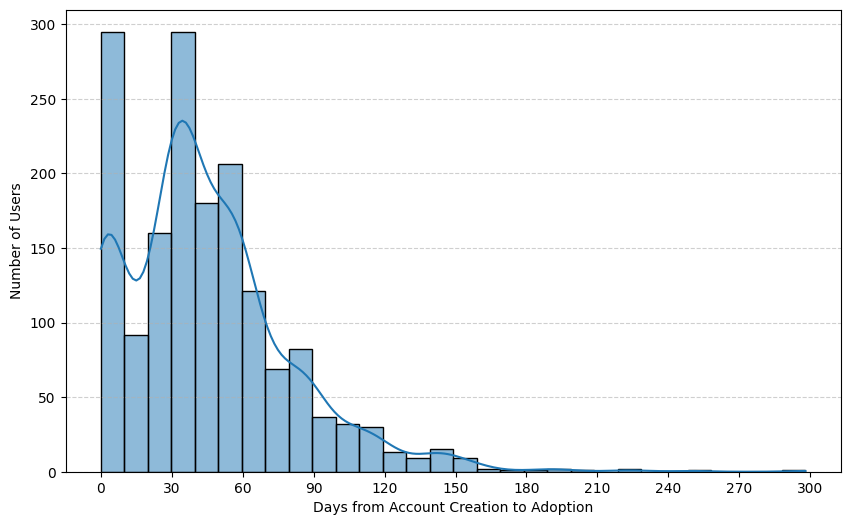

In [45]:
plt.figure(figsize=(10, 6))
sns.histplot(adopted['days_to_adopt'], bins=30, kde=True)

plt.xlabel("Days from Account Creation to Adoption")
plt.ylabel("Number of Users")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(range(0, 310, 30));

#### We see that most adopted users reach adoption status within the first 30 days of account creation, particularly in the first 10 to 30 days. This highlights the importance of early engagement.

In [ ]:
final_df = final_df.merge(adopted[['user_id', 'days_to_adopt']], on='user_id', how='left') 
final_df

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id,account_age,adopted,days_to_adopt
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,2014-04-22 03:53:30,1,0,11,10803.0,0,False,NaN
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,2014-03-31 03:45:04,0,0,1,316.0,136,True,80.0
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,2013-03-19 23:14:52,0,0,94,1525.0,0,False,NaN
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,2013-05-22 08:09:28,0,0,1,5151.0,1,False,NaN
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,2013-01-22 10:14:20,0,0,193,5240.0,5,False,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,11996,2013-09-06 06:14:15,Meier Sophia,SophiaMeier@gustr.com,ORG_INVITE,2013-09-06 06:14:15,0,0,89,8263.0,0,False,NaN
11996,11997,2013-01-10 18:28:37,Fisher Amelie,AmelieFisher@gmail.com,SIGNUP_GOOGLE_AUTH,2013-01-15 18:28:37,0,0,200,NaN,5,False,NaN
11997,11998,2014-04-27 12:45:16,Haynes Jake,JakeHaynes@cuvox.de,GUEST_INVITE,2014-04-27 12:45:16,1,1,83,8074.0,0,False,NaN
11998,11999,2012-05-31 11:55:59,Faber Annett,mhaerzxp@iuxiw.com,PERSONAL_PROJECTS,2012-06-02 11:55:59,0,0,6,NaN,2,False,NaN


#### We see that organizations vary in size, we'll feature this into `org_size` that counts the number of users for a respected organization 

In [15]:
final_df['org_id'].value_counts()

org_id
0      319
1      233
2      201
3      168
4      159
      ... 
396      9
400      8
397      8
386      7
416      2
Name: count, Length: 417, dtype: int64

In [16]:
org_sizes = final_df['org_id'].value_counts().to_dict()
final_df['org_size'] = final_df['org_id'].map(org_sizes)

#### The `invited_by_user` doesn't give much information when modeling, so we'll create a binary column telling us if a user was invited or not called `was_invited` then in the modeling phase we'll drop `invited_by_user`

In [17]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   user_id                     12000 non-null  int64         
 1   creation_time               12000 non-null  datetime64[ns]
 2   name                        12000 non-null  object        
 3   email                       12000 non-null  object        
 4   creation_source             12000 non-null  object        
 5   last_session_creation_time  12000 non-null  datetime64[ns]
 6   opted_in_to_mailing_list    12000 non-null  int64         
 7   enabled_for_marketing_drip  12000 non-null  int64         
 8   org_id                      12000 non-null  int64         
 9   invited_by_user_id          6417 non-null   float64       
 10  account_age                 12000 non-null  int64         
 11  adopted                     12000 non-null  bool      

In [18]:
final_df['was_invited'] = final_df['invited_by_user_id'].notnull().astype(int)
final_df

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id,account_age,adopted,days_to_adopt,org_size,was_invited
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,2014-04-22 03:53:30,1,0,11,10803.0,0,False,NaN,75,1
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,2014-03-31 03:45:04,0,0,1,316.0,136,True,80.0,233,1
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,2013-03-19 23:14:52,0,0,94,1525.0,0,False,NaN,32,1
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,2013-05-22 08:09:28,0,0,1,5151.0,1,False,NaN,233,1
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,2013-01-22 10:14:20,0,0,193,5240.0,5,False,NaN,16,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,11996,2013-09-06 06:14:15,Meier Sophia,SophiaMeier@gustr.com,ORG_INVITE,2013-09-06 06:14:15,0,0,89,8263.0,0,False,NaN,40,1
11996,11997,2013-01-10 18:28:37,Fisher Amelie,AmelieFisher@gmail.com,SIGNUP_GOOGLE_AUTH,2013-01-15 18:28:37,0,0,200,NaN,5,False,NaN,25,0
11997,11998,2014-04-27 12:45:16,Haynes Jake,JakeHaynes@cuvox.de,GUEST_INVITE,2014-04-27 12:45:16,1,1,83,8074.0,0,False,NaN,27,1
11998,11999,2012-05-31 11:55:59,Faber Annett,mhaerzxp@iuxiw.com,PERSONAL_PROJECTS,2012-06-02 11:55:59,0,0,6,NaN,2,False,NaN,138,0


#### I also want to see if some organizations are better in adopting users than others as each company has its own culture and different expectations, I'll determine this depending on the size of a organization 

In [19]:
org_adopted_counts = final_df[final_df['adopted'] == True].groupby('org_id').size().reset_index(name='num_adopted')
org_adopted_counts = org_adopted_counts.sort_values(by='num_adopted', ascending=False)
org_adopted_counts.head()

,org_id,num_adopted
4,4,17
7,7,16
1,1,16
2,2,15
13,13,14


In [20]:
org_adopted_counts = org_adopted_counts.merge(
    final_df[['org_id', 'org_size']].drop_duplicates(),
    on='org_id'
)
org_adopted_counts = org_adopted_counts.sort_values(by='num_adopted', ascending=False)
org_adopted_counts.head(10)

,org_id,num_adopted,org_size
0,4,17,159
2,1,16,233
1,7,16,119
3,2,15,201
6,3,14,168
4,13,14,72
5,9,14,124
9,0,12,319
8,5,12,128
7,62,12,39


#### We see a mix of large and small organization adopting high users, although we see more higher sized organizations this could be due to simply having more users than other companies. For this criteria to be modeled, I'll rank the org_size from 1 to 4   

In [21]:
org_df = final_df[['org_id', 'org_size']].drop_duplicates().sort_values(by='org_size', ascending=False)
org_df

,org_id,org_size
13,0,319
1,1,233
17,2,201
96,3,168
44,4,159
...,...,...
4527,396,9
1463,400,8
1926,397,8
960,386,7


In [22]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init='auto')
org_df['org_size_rank'] = kmeans.fit_predict(org_df[['org_size']])
cluster_order = org_df.groupby('org_size_rank')['org_size'].mean().sort_values().index
rank_mapping = {cluster: rank + 1 for rank, cluster in enumerate(cluster_order)} # creating mapping higher rank = larger size
org_df['org_size_rank'] = org_df['org_size_rank'].map(rank_mapping)
org_df.head(10)

,org_id,org_size,org_size_rank
13,0,319,4
1,1,233,3
17,2,201,3
96,3,168,3
44,4,159,3
22,6,138,3
67,5,128,3
136,9,124,3
21,7,119,3
89,10,104,2


In [23]:
org_df['org_size_rank'].value_counts().sort_index()

org_size_rank
1    342
2     66
3      8
4      1
Name: count, dtype: int64

In [24]:
final_df = final_df.merge(org_df[['org_id', 'org_size_rank']], on='org_id', how='left')
final_df

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id,account_age,adopted,days_to_adopt,org_size,was_invited,org_size_rank
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,2014-04-22 03:53:30,1,0,11,10803.0,0,False,NaN,75,1,2
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,2014-03-31 03:45:04,0,0,1,316.0,136,True,80.0,233,1,3
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,2013-03-19 23:14:52,0,0,94,1525.0,0,False,NaN,32,1,1
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,2013-05-22 08:09:28,0,0,1,5151.0,1,False,NaN,233,1,3
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,2013-01-22 10:14:20,0,0,193,5240.0,5,False,NaN,16,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,11996,2013-09-06 06:14:15,Meier Sophia,SophiaMeier@gustr.com,ORG_INVITE,2013-09-06 06:14:15,0,0,89,8263.0,0,False,NaN,40,1,2
11996,11997,2013-01-10 18:28:37,Fisher Amelie,AmelieFisher@gmail.com,SIGNUP_GOOGLE_AUTH,2013-01-15 18:28:37,0,0,200,NaN,5,False,NaN,25,0,1
11997,11998,2014-04-27 12:45:16,Haynes Jake,JakeHaynes@cuvox.de,GUEST_INVITE,2014-04-27 12:45:16,1,1,83,8074.0,0,False,NaN,27,1,1
11998,11999,2012-05-31 11:55:59,Faber Annett,mhaerzxp@iuxiw.com,PERSONAL_PROJECTS,2012-06-02 11:55:59,0,0,6,NaN,2,False,NaN,138,0,3


#### Creating `total_visits` to see the total amount of times a user visits this product

In [25]:
visit_counts = engage.groupby('user_id').size().reset_index(name='total_visits')
final_df = final_df.merge(visit_counts, on='user_id', how='left')
final_df['total_visits'] = final_df['total_visits'].fillna(0).astype(int)
final_df

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id,account_age,adopted,days_to_adopt,org_size,was_invited,org_size_rank,total_visits
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,2014-04-22 03:53:30,1,0,11,10803.0,0,False,NaN,75,1,2,1
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,2014-03-31 03:45:04,0,0,1,316.0,136,True,80.0,233,1,3,14
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,2013-03-19 23:14:52,0,0,94,1525.0,0,False,NaN,32,1,1,1
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,2013-05-22 08:09:28,0,0,1,5151.0,1,False,NaN,233,1,3,1
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,2013-01-22 10:14:20,0,0,193,5240.0,5,False,NaN,16,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,11996,2013-09-06 06:14:15,Meier Sophia,SophiaMeier@gustr.com,ORG_INVITE,2013-09-06 06:14:15,0,0,89,8263.0,0,False,NaN,40,1,2,1
11996,11997,2013-01-10 18:28:37,Fisher Amelie,AmelieFisher@gmail.com,SIGNUP_GOOGLE_AUTH,2013-01-15 18:28:37,0,0,200,NaN,5,False,NaN,25,0,1,1
11997,11998,2014-04-27 12:45:16,Haynes Jake,JakeHaynes@cuvox.de,GUEST_INVITE,2014-04-27 12:45:16,1,1,83,8074.0,0,False,NaN,27,1,1,1
11998,11999,2012-05-31 11:55:59,Faber Annett,mhaerzxp@iuxiw.com,PERSONAL_PROJECTS,2012-06-02 11:55:59,0,0,6,NaN,2,False,NaN,138,0,3,1


#### Creating `creation_month` to determine the month a user was created, which can possibly give some insight

In [26]:
final_df['creation_month'] = final_df['creation_time'].dt.strftime('%B')
final_df

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id,account_age,adopted,days_to_adopt,org_size,was_invited,org_size_rank,total_visits,creation_month
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,2014-04-22 03:53:30,1,0,11,10803.0,0,False,NaN,75,1,2,1,April
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,2014-03-31 03:45:04,0,0,1,316.0,136,True,80.0,233,1,3,14,November
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,2013-03-19 23:14:52,0,0,94,1525.0,0,False,NaN,32,1,1,1,March
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,2013-05-22 08:09:28,0,0,1,5151.0,1,False,NaN,233,1,3,1,May
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,2013-01-22 10:14:20,0,0,193,5240.0,5,False,NaN,16,1,1,1,January
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,11996,2013-09-06 06:14:15,Meier Sophia,SophiaMeier@gustr.com,ORG_INVITE,2013-09-06 06:14:15,0,0,89,8263.0,0,False,NaN,40,1,2,1,September
11996,11997,2013-01-10 18:28:37,Fisher Amelie,AmelieFisher@gmail.com,SIGNUP_GOOGLE_AUTH,2013-01-15 18:28:37,0,0,200,NaN,5,False,NaN,25,0,1,1,January
11997,11998,2014-04-27 12:45:16,Haynes Jake,JakeHaynes@cuvox.de,GUEST_INVITE,2014-04-27 12:45:16,1,1,83,8074.0,0,False,NaN,27,1,1,1,April
11998,11999,2012-05-31 11:55:59,Faber Annett,mhaerzxp@iuxiw.com,PERSONAL_PROJECTS,2012-06-02 11:55:59,0,0,6,NaN,2,False,NaN,138,0,3,1,May


#### Its also interesting to identify the time gaps between visits so we can obtain the `avg_days_between_logins`, on top of that we can also derive the standard deviation between these vists to create `std_gap_days`

In [27]:
engage['date'] = engage['time_stamp'].dt.date
engage = engage.sort_values(['user_id', 'date'])
unique_days = engage.drop_duplicates(subset=['user_id', 'date'])

def compute_streaks(dates):
    streak = 0
    max_streak = 0
    prev_date = None
    for date in dates:
        if prev_date is not None and (date - prev_date).days == 1:
            streak += 1
        else:
            streak = 1
        prev_date = date
        max_streak = max(max_streak, streak)
    return max_streak

streaks = (unique_days.groupby('user_id')['date']
           .apply(lambda x: compute_streaks(sorted(x)))
           .reset_index(name='max_login_streak'))

In [28]:
engage = engage.sort_values(['user_id', 'time_stamp'])
engage['time_diff'] = engage.groupby('user_id')['time_stamp'].diff()

avg_gap = engage.groupby('user_id')['time_diff'].mean().reset_index()
avg_gap['avg_days_between_logins'] = avg_gap['time_diff'].dt.days
avg_gap = avg_gap.drop(columns='time_diff')

final_df = final_df.merge(streaks, on='user_id', how='left')
final_df = final_df.merge(avg_gap, on='user_id', how='left')
final_df

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id,account_age,adopted,days_to_adopt,org_size,was_invited,org_size_rank,total_visits,creation_month,max_login_streak,avg_days_between_logins
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,2014-04-22 03:53:30,1,0,11,10803.0,0,False,NaN,75,1,2,1,April,1.0,NaN
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,2014-03-31 03:45:04,0,0,1,316.0,136,True,80.0,233,1,3,14,November,2.0,10.0
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,2013-03-19 23:14:52,0,0,94,1525.0,0,False,NaN,32,1,1,1,March,1.0,NaN
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,2013-05-22 08:09:28,0,0,1,5151.0,1,False,NaN,233,1,3,1,May,1.0,NaN
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,2013-01-22 10:14:20,0,0,193,5240.0,5,False,NaN,16,1,1,1,January,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,11996,2013-09-06 06:14:15,Meier Sophia,SophiaMeier@gustr.com,ORG_INVITE,2013-09-06 06:14:15,0,0,89,8263.0,0,False,NaN,40,1,2,1,September,1.0,NaN
11996,11997,2013-01-10 18:28:37,Fisher Amelie,AmelieFisher@gmail.com,SIGNUP_GOOGLE_AUTH,2013-01-15 18:28:37,0,0,200,NaN,5,False,NaN,25,0,1,1,January,1.0,NaN
11997,11998,2014-04-27 12:45:16,Haynes Jake,JakeHaynes@cuvox.de,GUEST_INVITE,2014-04-27 12:45:16,1,1,83,8074.0,0,False,NaN,27,1,1,1,April,1.0,NaN
11998,11999,2012-05-31 11:55:59,Faber Annett,mhaerzxp@iuxiw.com,PERSONAL_PROJECTS,2012-06-02 11:55:59,0,0,6,NaN,2,False,NaN,138,0,3,1,May,1.0,NaN


In [29]:
std_gap = engage.groupby('user_id')['time_stamp'].apply(lambda x: x.sort_values().diff().dt.days.std()).reset_index(name='std_gap_days')
final_df = final_df.merge(std_gap, on='user_id', how='left')
final_df

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id,...,adopted,days_to_adopt,org_size,was_invited,org_size_rank,total_visits,creation_month,max_login_streak,avg_days_between_logins,std_gap_days
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,2014-04-22 03:53:30,1,0,11,10803.0,...,False,NaN,75,1,2,1,April,1.0,NaN,NaN
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,2014-03-31 03:45:04,0,0,1,316.0,...,True,80.0,233,1,3,14,November,2.0,10.0,7.838105
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,2013-03-19 23:14:52,0,0,94,1525.0,...,False,NaN,32,1,1,1,March,1.0,NaN,NaN
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,2013-05-22 08:09:28,0,0,1,5151.0,...,False,NaN,233,1,3,1,May,1.0,NaN,NaN
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,2013-01-22 10:14:20,0,0,193,5240.0,...,False,NaN,16,1,1,1,January,1.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,11996,2013-09-06 06:14:15,Meier Sophia,SophiaMeier@gustr.com,ORG_INVITE,2013-09-06 06:14:15,0,0,89,8263.0,...,False,NaN,40,1,2,1,September,1.0,NaN,NaN
11996,11997,2013-01-10 18:28:37,Fisher Amelie,AmelieFisher@gmail.com,SIGNUP_GOOGLE_AUTH,2013-01-15 18:28:37,0,0,200,NaN,...,False,NaN,25,0,1,1,January,1.0,NaN,NaN
11997,11998,2014-04-27 12:45:16,Haynes Jake,JakeHaynes@cuvox.de,GUEST_INVITE,2014-04-27 12:45:16,1,1,83,8074.0,...,False,NaN,27,1,1,1,April,1.0,NaN,NaN
11998,11999,2012-05-31 11:55:59,Faber Annett,mhaerzxp@iuxiw.com,PERSONAL_PROJECTS,2012-06-02 11:55:59,0,0,6,NaN,...,False,NaN,138,0,3,1,May,1.0,NaN,NaN


## EDA
#### We'll explore user demographics, engagement behavior, and temporal activity patterns to uncover trends and signals that may influence product adoption

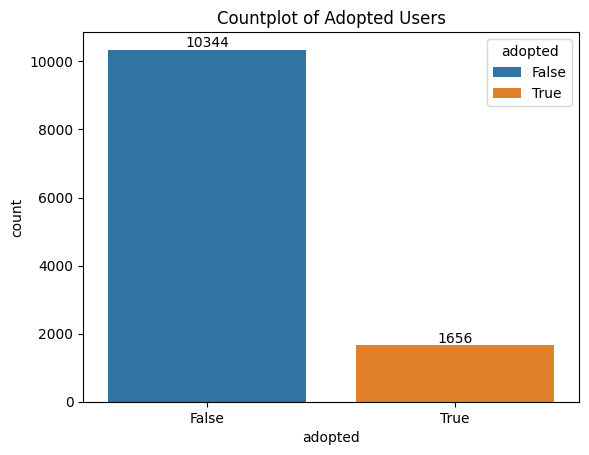

In [30]:
ax = sns.countplot(x='adopted', hue='adopted', data=final_df)
plt.title('Countplot of Adopted Users');

for container in ax.containers:
    ax.bar_label(container)

#### This shows a significant class imbalance, with only 1,656 users (≈14%) classified as adopted compared to 10,344 non-adopted users, we'll address this imbalance during modeling

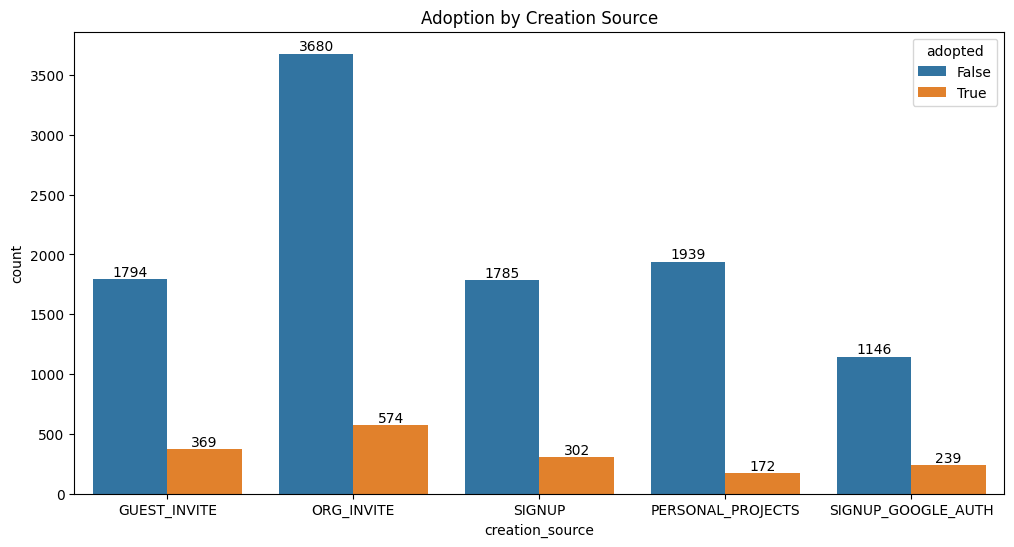

In [31]:
plt.figure(figsize=(12, 6))
ax = sns.countplot(x='creation_source', hue='adopted', data=final_df)
plt.title('Adoption by Creation Source');

for container in ax.containers:
    ax.bar_label(container)

#### We see that users who joined via ORG_INVITE had the highest number of adoptions, while adoption counts across the other creation sources are relatively similar with PERSONAL_PROJECTS ranking last

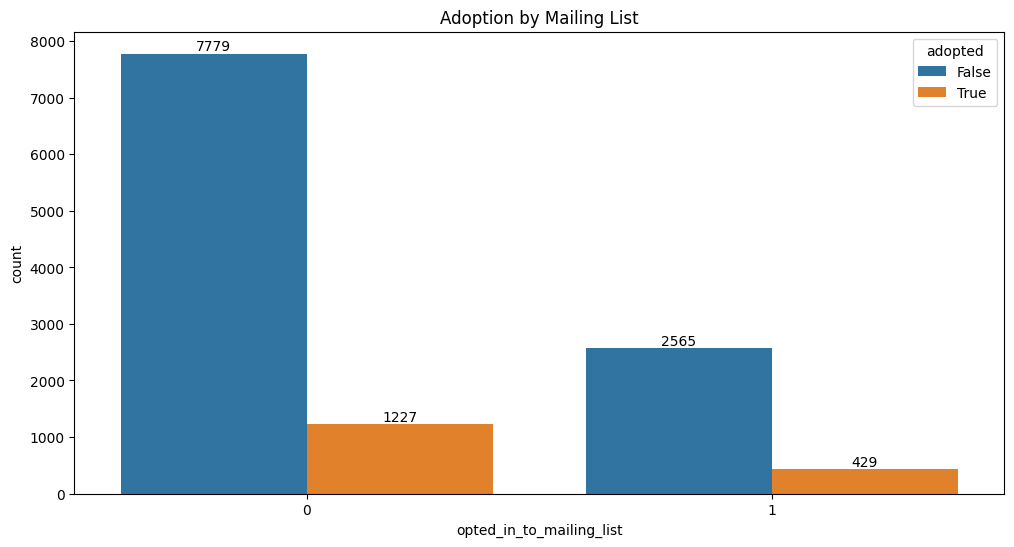

In [32]:
plt.figure(figsize=(12, 6))
ax = sns.countplot(x='opted_in_to_mailing_list', hue='adopted', data=final_df)
plt.title('Adoption by Mailing List')

for container in ax.containers:
    ax.bar_label(container)

#### While users who did not opt into the mailing list show a higher number of adoptions, this is primarily because that group contains significantly more users, and not because opting out is associated with higher adoption rate

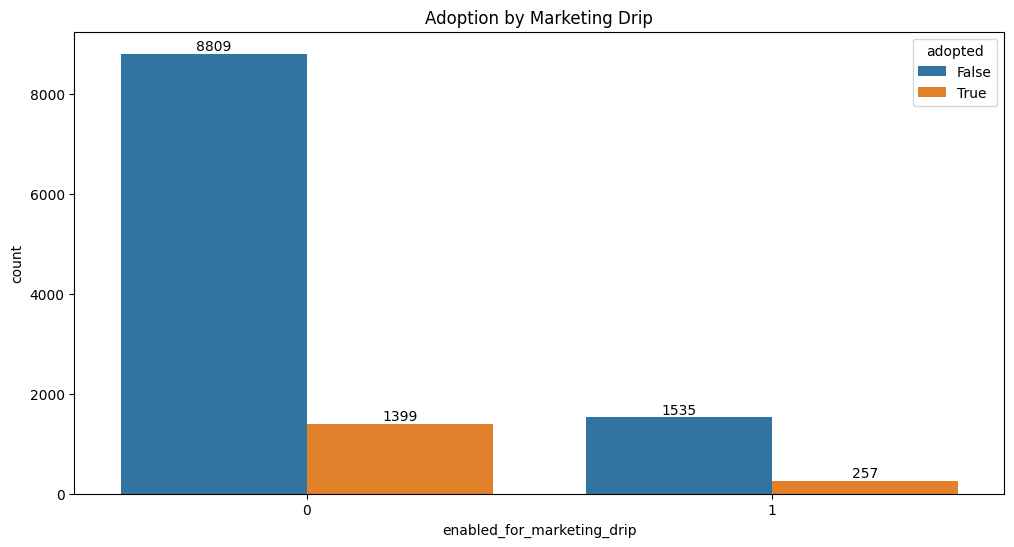

In [33]:
plt.figure(figsize=(12, 6))
ax = sns.countplot(x='enabled_for_marketing_drip', hue='adopted', data=final_df)
plt.title('Adoption by Marketing Drip')

for container in ax.containers:
    ax.bar_label(container)

#### Same is seen here as in "Adoption by Mailing List"

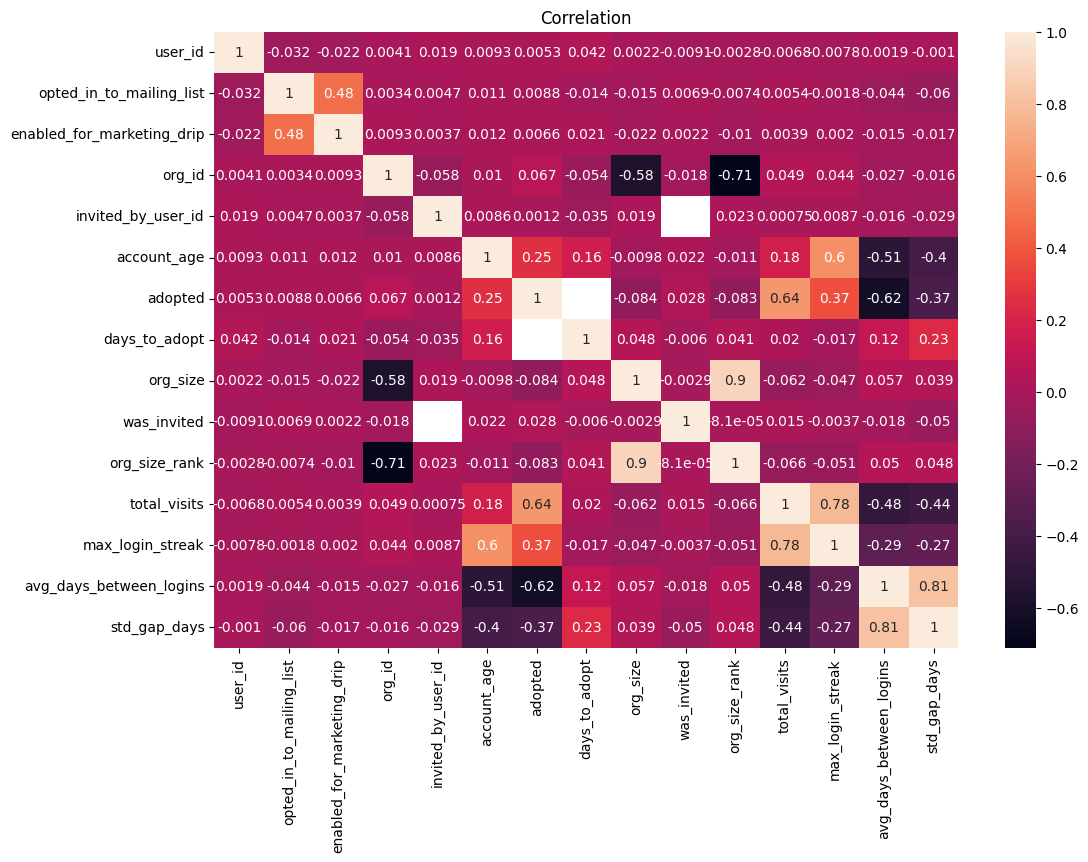

In [34]:
plt.figure(figsize = (12,8))
plt.title('Correlation')
sns.heatmap(final_df.corr(numeric_only=True), annot=True);

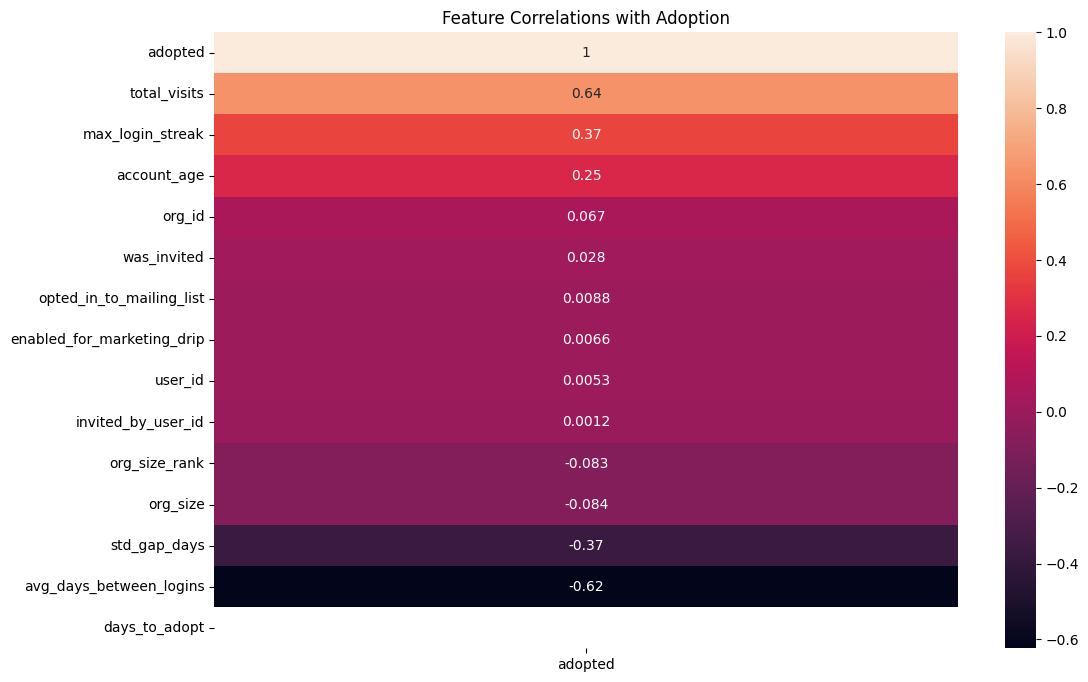

In [35]:
plt.figure(figsize = (12,8))
plt.title('Feature Correlations with Adoption')
sns.heatmap(final_df.corr(numeric_only=True)[['adopted']].sort_values(by = 'adopted',ascending = False), annot=True);

#### Adopted users have characteristics of:
- High total visits
- Long login streaks
- Low average days between logins
- Low variability in session gaps

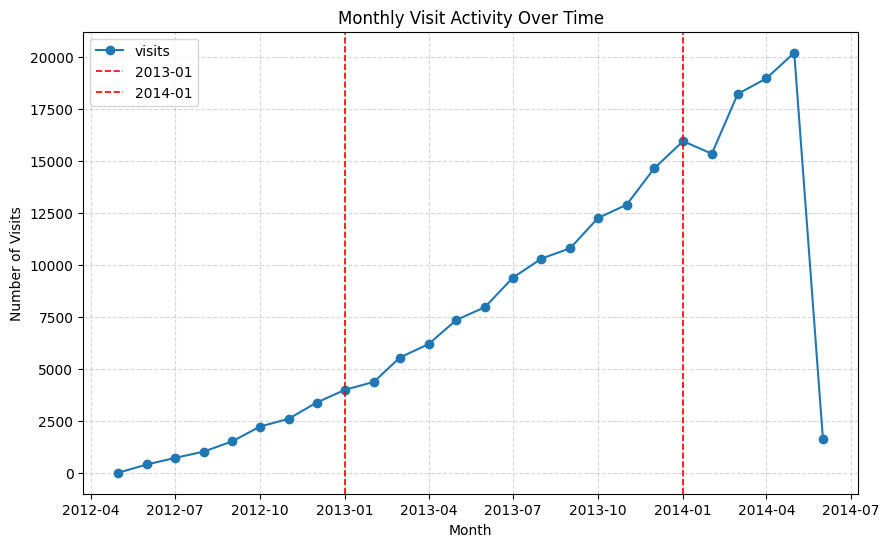

In [ ]:
df = (engage
 .assign(monthly=engage['time_stamp'].dt.to_period('M').dt.to_timestamp())
 .groupby('monthly')
 .size()
 .reset_index(name='visits')
)

plt.figure(figsize=(10, 6))
plt.plot(df['monthly'], df['visits'], marker='o', label='visits')

for year in [2013, 2014]:
    plt.axvline(pd.Timestamp(f'{year}-01-01'), color='red', linestyle='--', linewidth=1.2, label=f'{year}-01')

plt.title("Monthly Visit Activity Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Visits")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend();

#### We see that product activity grew steadily year over year, with a sharp decline in June 2014 likely due to incomplete or missing data

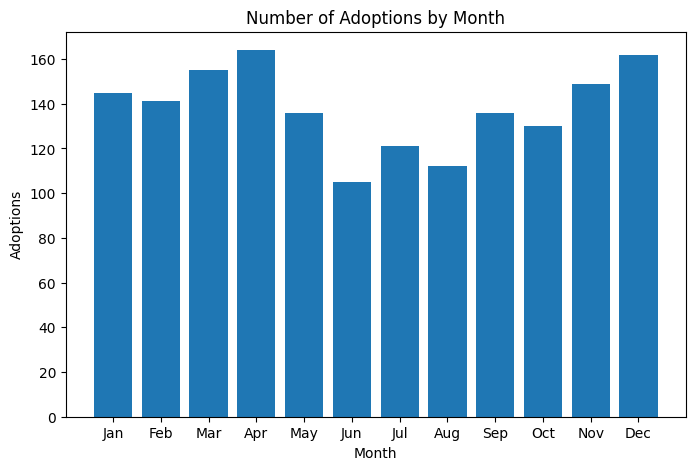

In [37]:
adopted['adoption_month'] = adopted['adoption_date'].dt.month
month_counts = adopted['adoption_month'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(month_counts.index, month_counts.values)
plt.xticks(ticks=range(1, 13), labels=[
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
])
plt.title("Number of Adoptions by Month")
plt.xlabel("Month")
plt.ylabel("Adoptions");

#### This shows slight monthly variation in adoption counts, with peaks in April and December, but overall the differences are relatively minor

## Modeling
#### To predict user adoption, we'll use a logistic regression classifier for its interpretability in binary classification

In [38]:
final_df

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id,...,adopted,days_to_adopt,org_size,was_invited,org_size_rank,total_visits,creation_month,max_login_streak,avg_days_between_logins,std_gap_days
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,2014-04-22 03:53:30,1,0,11,10803.0,...,False,NaN,75,1,2,1,April,1.0,NaN,NaN
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,2014-03-31 03:45:04,0,0,1,316.0,...,True,80.0,233,1,3,14,November,2.0,10.0,7.838105
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,2013-03-19 23:14:52,0,0,94,1525.0,...,False,NaN,32,1,1,1,March,1.0,NaN,NaN
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,2013-05-22 08:09:28,0,0,1,5151.0,...,False,NaN,233,1,3,1,May,1.0,NaN,NaN
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,2013-01-22 10:14:20,0,0,193,5240.0,...,False,NaN,16,1,1,1,January,1.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,11996,2013-09-06 06:14:15,Meier Sophia,SophiaMeier@gustr.com,ORG_INVITE,2013-09-06 06:14:15,0,0,89,8263.0,...,False,NaN,40,1,2,1,September,1.0,NaN,NaN
11996,11997,2013-01-10 18:28:37,Fisher Amelie,AmelieFisher@gmail.com,SIGNUP_GOOGLE_AUTH,2013-01-15 18:28:37,0,0,200,NaN,...,False,NaN,25,0,1,1,January,1.0,NaN,NaN
11997,11998,2014-04-27 12:45:16,Haynes Jake,JakeHaynes@cuvox.de,GUEST_INVITE,2014-04-27 12:45:16,1,1,83,8074.0,...,False,NaN,27,1,1,1,April,1.0,NaN,NaN
11998,11999,2012-05-31 11:55:59,Faber Annett,mhaerzxp@iuxiw.com,PERSONAL_PROJECTS,2012-06-02 11:55:59,0,0,6,NaN,...,False,NaN,138,0,3,1,May,1.0,NaN,NaN


In [39]:
X = final_df.drop(columns=[
    'user_id',
    'name',
    'email',
    'days_to_adopt',
    'adopted',
    'invited_by_user_id',
    'creation_time',
    'last_session_creation_time'
])

y = final_df['adopted']

In [40]:
X = pd.get_dummies(X, columns=['creation_source', 'org_size_rank', 'creation_month'], drop_first=False)

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [42]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
 
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1] 

In [43]:
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_proba))

Confusion Matrix:
 [[2060    9]
 [  18  313]]

Classification Report:
               precision    recall  f1-score   support

       False       0.99      1.00      0.99      2069
        True       0.97      0.95      0.96       331

    accuracy                           0.99      2400
   macro avg       0.98      0.97      0.98      2400
weighted avg       0.99      0.99      0.99      2400

ROC AUC Score: 0.9992596800123824


#### The Random Forest Classifier achieved excellent performance with an accuracy of 99%, a precision of 97% for adopted users, and an ROC AUC score of 0.999

Text(0.5, 1.0, 'Feature Importance')

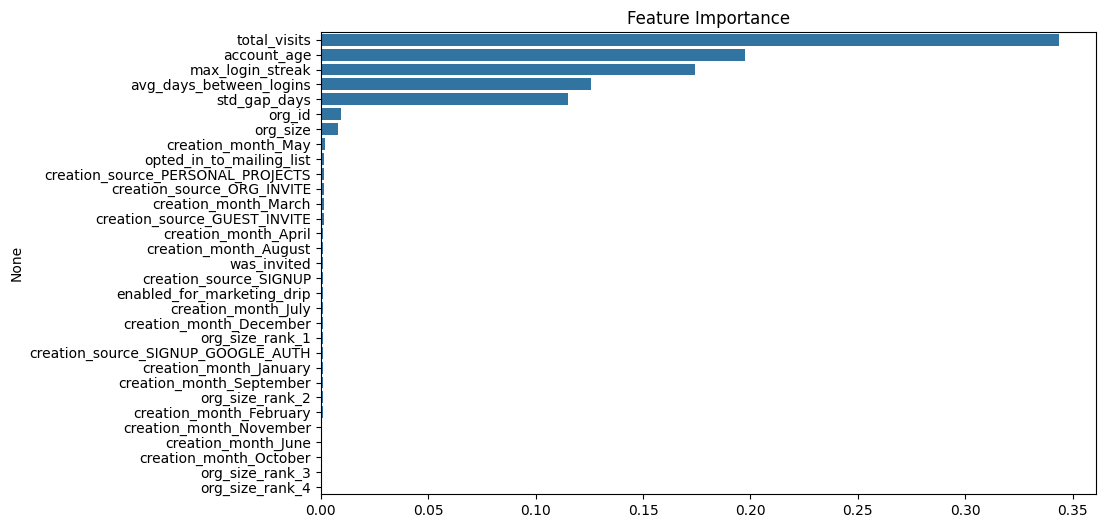

In [44]:
feat_importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_importances.values, y=feat_importances.index)
plt.title("Feature Importance")

#### This shows that total visits is by far the most influential predictor of user adoption, followed by account age, max login streak, and login timing features like average days between logins and std gap days. These top features suggest that adoption is strongly driven by how actively and regularly users engage with the platform. In contrast, variables related to creation source, marketing preferences, and organizational factors contributed very little to the model's performance

## Conclusion

#### This analysis aimed to understand the factors that influence user adoption and to build a predictive model capable of identifying potential users. Through exploratory data analysis, we observed that:
- #### Adopted users tend to engage with the platform early, frequently, and consistently often adopting within the first 30 days of account creation
- #### Behavioral metrics such as total visits, login streaks, and session timing patterns emerged as key factors between adopted and non-adopted users
#### Using a logistic regression classifier, we were able to effectively model the adoption outcome, with feature importance analysis confirming that engagement related features were far more predictive than user metadata.
#### Overall, the findings highlight the critical role of early and consistent engagement in driving user adoption. These insights can inform onboarding strategies and retention focused interventions, specifically during the first few weeks of a user's lifecycle.